<a href="https://colab.research.google.com/github/CristianMP355/Homepets/blob/main/Miniproyecto_CNN_AlphaDent_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Miniproyecto CNN: detección y segmentación de instancias en fotos dentales (AlphaDent)

En este proyecto entrenamos una red neuronal convolucional que recibe una fotografía de la boca y, para cada lesión o restauración que encuentra, entrega las tres cosas que pide la consigna: la clase (de qué tipo es), las coordenadas de la caja que la encierra y la máscara con su contorno.

Datos del proyecto:
- Dataset: AlphaDent (competencia de Kaggle, https://www.kaggle.com/competitions/alpha-dent/data). Quedamos con 1.320 fotos etiquetadas de 293 pacientes y 12.872 objetos válidos, repartidos en 9 clases (la consigna pide mínimo 5).
- Modelo: YOLOv8n-seg, una red de una sola etapa, partiendo de pesos preentrenados en COCO y reentrenada con nuestras 9 clases.
- Dos corridas: imágenes de 640 px y de 1024 px, para ver si la resolución explica los errores.
- Evaluación: conjunto de prueba propio (45 pacientes, 190 fotos) que el modelo nunca vio.

Para ejecutarlo hay que activar la GPU (Entorno de ejecución > Cambiar tipo de entorno > GPU), tener la cuenta de Kaggle con las reglas de la competencia aceptadas y subir el kaggle.json cuando la celda lo pida. Los resultados se guardan en Google Drive.

Es un trabajo académico; el modelo no sirve como herramienta de diagnóstico.

## 1. Configuración del entorno

In [ ]:
from google.colab import drive
from pathlib import Path
import os, random, shutil, json, glob, zipfile, subprocess, sys
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Montar Drive para conservar los pesos, las métricas y las gráficas.
drive.mount('/content/drive')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('GPU disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print('Activa una GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución.')

%pip -q install -U ultralytics kaggle pyyaml

Mounted at /content/drive
GPU disponible: True
Tesla T4
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.7 MB/s eta 0:00:00


## 2. Descarga del dataset

Los datos están en la competencia AlphaDent de Kaggle y los bajamos con la API de Kaggle. Hay que haber aceptado las reglas de la competencia en la página y subir el archivo kaggle.json de la cuenta. Ese archivo tiene credenciales, así que no se comparte.

In [ ]:
from google.colab import files

uploaded = files.upload()  # Selecciona kaggle.json
if 'kaggle.json' not in uploaded:
    raise FileNotFoundError('No se cargó kaggle.json. Vuelve a ejecutar esta celda y selecciónalo.')

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print('Credenciales configuradas solo en el entorno de Colab.')

Saving kaggle.json to kaggle.json
Credenciales configuradas solo en el entorno de Colab.


In [ ]:
DATA_DIR = Path('/content/data')
ZIP_PATH = DATA_DIR / 'alpha-dent.zip'
BASE = DATA_DIR / 'AlphaDent'
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not BASE.exists():
    !kaggle competitions download -c alpha-dent -p /content/data
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f'No se encontró {ZIP_PATH}. Revisa que hayas aceptado las reglas de Kaggle.')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(DATA_DIR)

print('Dataset encontrado:', BASE.exists())
print('Carpeta:', BASE)
print('Subcarpetas:', [p.name for p in BASE.iterdir()] if BASE.exists() else 'No encontrada')

100% 4.56G/4.56G [00:45<00:00, 107MB/s] 

Dataset encontrado: True
Carpeta: /content/data/AlphaDent
Subcarpetas: ['yolo_seg_train.yaml', 'labels', 'images']


## 3. Estructura del dataset, clases y etiquetas

Cada foto tiene un archivo .txt con una línea por objeto: el número de clase y después los puntos (x, y) del contorno, normalizados entre 0 y 1. De ese contorno salen las tres etiquetas que pide la consigna: la clase es el primer número, la máscara es el polígono y la caja se calcula con el mínimo y el máximo de x y de y del polígono. El dataset no trae máscaras en imágenes PNG, solo estos polígonos, y son los que usa YOLOv8-seg para entrenar.

Al revisar los archivos encontramos 32 líneas con solo uno o dos puntos, que no forman una región (el 0,25 % de las instancias). En el primer entrenamiento Ultralytics descartaba esas fotos completas con el aviso "labels mix segment and detection rows" (10 fotos de entrenamiento y 1 de validación). Por eso escribimos una función que filtra esas líneas antes de entrenar y las cuenta.

Para explicar: ¿por qué hay que limpiar? Porque un polígono de menos de 3 puntos no tiene área y confunde a la función de pérdida de la máscara.

In [ ]:
import yaml

yaml_candidates = list(BASE.rglob('*.yaml')) + list(BASE.rglob('*.yml'))
if not yaml_candidates:
    raise FileNotFoundError('No se encontró el YAML de clases en AlphaDent.')
SOURCE_YAML = yaml_candidates[0]
source_cfg = yaml.safe_load(SOURCE_YAML.read_text())
names = source_cfg.get('names')
if isinstance(names, dict):
    CLASS_NAMES = [names[i] for i in sorted(names)]
else:
    CLASS_NAMES = list(names)

print('Archivo de configuración:', SOURCE_YAML)
print('Número de clases:', len(CLASS_NAMES))
for i, name in enumerate(CLASS_NAMES):
    print(f'{i}: {name}')
assert len(CLASS_NAMES) >= 5, 'El dataset debe tener al menos cinco clases.'

for part in ('train', 'valid', 'test'):
    img_dir = BASE / 'images' / part
    lab_dir = BASE / 'labels' / part
    print(f'{part}: imágenes={len(list(img_dir.glob("*.jpg"))) if img_dir.exists() else 0}; etiquetas={len(list(lab_dir.glob("*.txt"))) if lab_dir.exists() else 0}')

Archivo de configuración: /content/data/AlphaDent/yolo_seg_train.yaml
Número de clases: 9
0: Abrasion
1: Filling
2: Crown
3: Caries 1 class
4: Caries 2 class
5: Caries 3 class
6: Caries 4 class
7: Caries 5 class
8: Caries 6 class
train: imágenes=1237; etiquetas=1237
valid: imágenes=83; etiquetas=83
test: imágenes=135; etiquetas=0


In [ ]:
# Inventario de imágenes etiquetadas. Solo train y valid tienen etiquetas disponibles.
image_label_pairs = []
for part in ('train', 'valid'):
    img_dir = BASE / 'images' / part
    lab_dir = BASE / 'labels' / part
    if not img_dir.exists() or not lab_dir.exists():
        continue
    for img_path in sorted(img_dir.glob('*')):
        if img_path.suffix.lower() not in ('.jpg', '.jpeg', '.png'):
            continue
        label_path = lab_dir / f'{img_path.stem}.txt'
        if label_path.exists():
            image_label_pairs.append((img_path, label_path))

if not image_label_pairs:
    raise RuntimeError('No se encontraron pares imagen-etiqueta en train/valid. Revisa la estructura descargada.')

print('Pares imagen-etiqueta:', len(image_label_pairs))
print('Ejemplo:', image_label_pairs[0][0].name, '->', image_label_pairs[0][1].name)

def read_valid_lines(label_path):
    """Devuelve (líneas válidas, líneas inválidas). Una instancia válida tiene clase 0-8
    y un polígono con al menos 3 vértices (6 valores) dentro de [0, 1]."""
    valid, invalid = [], []
    for ln, line in enumerate(Path(label_path).read_text().splitlines(), 1):
        v = line.split()
        if not v:
            continue
        try:
            cls = int(v[0])
            c = np.asarray(v[1:], dtype=float)
            ok = (0 <= cls < len(CLASS_NAMES) and len(c) >= 6 and len(c) % 2 == 0
                  and np.isfinite(c).all() and (c >= 0).all() and (c <= 1).all())
        except ValueError:
            ok = False
        (valid if ok else invalid).append((ln, line))
    return [l for _, l in valid], invalid

# Verificar el formato de las etiquetas, descartar polígonos degenerados y contar instancias por clase.
class_counts = Counter()
invalid_log = []          # (archivo, línea, contenido) de cada línea descartada
images_without_valid_instances = 0
patient_to_pairs = defaultdict(list)
for img_path, label_path in image_label_pairs:
    valid, invalid = read_valid_lines(label_path)
    invalid_log += [(label_path.name, ln, line) for ln, line in invalid]
    for line in valid:
        class_counts[int(line.split()[0])] += 1
    if not valid:
        images_without_valid_instances += 1
    patient_to_pairs[img_path.stem.split('_')[0]].append((img_path, label_path))

print('Pacientes identificados:', len(patient_to_pairs))
print('Líneas inválidas (se excluyen del entrenamiento):', len(invalid_log))
print('Imágenes sin instancias válidas:', images_without_valid_instances)
print('Total de instancias válidas:', sum(class_counts.values()))
assert images_without_valid_instances == 0, 'Hay imágenes sin ninguna instancia válida; revísalas.'
assert len(CLASS_NAMES) >= 5


Pares imagen-etiqueta: 1320
Ejemplo: p002_F_52_001.jpg -> p002_F_52_001.txt
Pacientes identificados: 293
Líneas inválidas (se excluyen del entrenamiento): 32
Imágenes sin instancias válidas: 0
Total de instancias válidas: 12872


,id_clase,clase,instancias
0,0,Abrasion,6347
1,1,Filling,2373
2,2,Crown,589
3,3,Caries 1 class,797
4,4,Caries 2 class,1098
5,5,Caries 3 class,505
6,6,Caries 4 class,47
7,7,Caries 5 class,1059
8,8,Caries 6 class,57


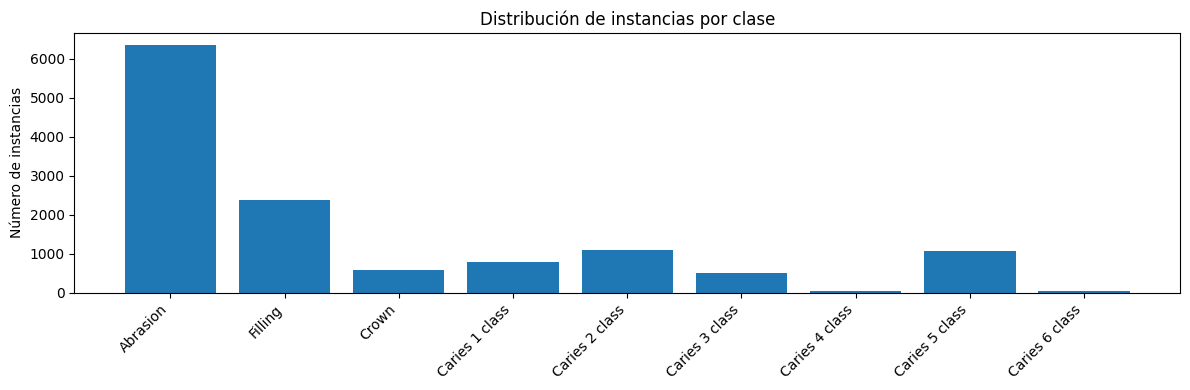

In [ ]:
# Distribución de instancias por clase: ayuda a detectar desbalance.
counts_df = pd.DataFrame({
    'id_clase': list(range(len(CLASS_NAMES))),
    'clase': CLASS_NAMES,
    'instancias': [class_counts[i] for i in range(len(CLASS_NAMES))]
})
display(counts_df)
plt.figure(figsize=(12, 4))
plt.bar(counts_df['clase'], counts_df['instancias'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Número de instancias')
plt.title('Distribución de instancias por clase')
plt.tight_layout()
plt.show()

## 4. Dataset propio y división por paciente

Juntamos las fotos con etiquetas de las carpetas train y valid de Kaggle (las de test no tienen etiquetas públicas) y armamos nuestra propia división 70 / 15 / 15 por paciente: 205 pacientes en entrenamiento, 43 en validación y 45 en prueba (952, 178 y 190 fotos).

Dividimos por paciente porque cada uno tiene varias fotos (hasta 18). Si una foto de un paciente queda en entrenamiento y otra en prueba, el modelo podría reconocer esa boca y las métricas saldrían más altas de lo real. La división es aleatoria con semilla fija (42), y el código comprueba que ningún paciente quede en dos conjuntos.

Limitación: el sorteo dejó muy pocos ejemplos de Caries 4 (2 objetos en prueba) y de Caries 6 (6 objetos). Con tan pocos casos las métricas de esas dos clases no se pueden interpretar.

In [ ]:
OUT_DIR = Path('/content/drive/MyDrive/miniproyecto_cnn')
CUSTOM = Path('/content/alphadent_custom')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Agrupar imágenes por paciente
patients = sorted(patient_to_pairs)
rng = random.Random(SEED)
rng.shuffle(patients)
n_patients = len(patients)
n_train = int(0.70 * n_patients)
n_val = int(0.15 * n_patients)
patient_split = {}
for i, patient in enumerate(patients):
    if i < n_train:
        patient_split[patient] = 'train'
    elif i < n_train + n_val:
        patient_split[patient] = 'val'
    else:
        patient_split[patient] = 'test'

# Crear estructura YOLO. Se copian imágenes y TXT; las máscaras se generan desde polígonos.
for split_name in ('train', 'val', 'test'):
    (CUSTOM / 'images' / split_name).mkdir(parents=True, exist_ok=True)
    (CUSTOM / 'labels' / split_name).mkdir(parents=True, exist_ok=True)

# Evitar mezclar ejecuciones anteriores con archivos obsoletos.
for split_name in ('train', 'val', 'test'):
    for folder in (CUSTOM / 'images' / split_name, CUSTOM / 'labels' / split_name):
        for old_file in folder.iterdir():
            if old_file.is_file(): old_file.unlink()

split_images = defaultdict(list)
for patient, pairs in patient_to_pairs.items():
    split_name = patient_split[patient]
    for img_path, label_path in pairs:
        shutil.copy2(img_path, CUSTOM / 'images' / split_name / img_path.name)
        valid_lines, _ = read_valid_lines(label_path)   # se escriben solo las instancias válidas
        (CUSTOM / 'labels' / split_name / label_path.name).write_text('\n'.join(valid_lines) + '\n')
        split_images[split_name].append(img_path.stem)

# Comprobar que ningún paciente aparece en más de un conjunto.
patient_sets = {s: {name.split('_')[0] for name in names} for s, names in split_images.items()}
assert not (patient_sets['train'] & patient_sets['val'])
assert not (patient_sets['train'] & patient_sets['test'])
assert not (patient_sets['val'] & patient_sets['test'])

print('Pacientes por conjunto:', {s: len(patient_sets[s]) for s in ('train','val','test')})
print('Imágenes por conjunto:', {s: len(split_images[s]) for s in ('train','val','test')})

# Crear YAML compatible con Ultralytics.
DATA_YAML = CUSTOM / 'alphadent.yaml'
yaml_cfg = {
    'path': str(CUSTOM),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {i: name for i, name in enumerate(CLASS_NAMES)},
}
DATA_YAML.write_text(yaml.safe_dump(yaml_cfg, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())

Pacientes por conjunto: {'train': 205, 'val': 43, 'test': 45}
Imágenes por conjunto: {'train': 952, 'val': 178, 'test': 190}
path: /content/alphadent_custom
train: images/train
val: images/val
test: images/test
names:
  0: Abrasion
  1: Filling
  2: Crown
  3: Caries 1 class
  4: Caries 2 class
  5: Caries 3 class
  6: Caries 4 class
  7: Caries 5 class
  8: Caries 6 class



In [ ]:
# Revisar el número de instancias por clase en cada partición.
split_counts = {s: Counter() for s in ('train', 'val', 'test')}
for s in ('train', 'val', 'test'):
    for label_path in (CUSTOM / 'labels' / s).glob('*.txt'):
        for line in label_path.read_text().splitlines():
            if line.strip():
                split_counts[s][int(line.split()[0])] += 1

dist = pd.DataFrame({
    'clase': CLASS_NAMES,
    'train': [split_counts['train'][i] for i in range(len(CLASS_NAMES))],
    'val': [split_counts['val'][i] for i in range(len(CLASS_NAMES))],
    'test': [split_counts['test'][i] for i in range(len(CLASS_NAMES))],
})
display(dist)
assert int(dist[['train', 'val', 'test']].sum().sum()) == sum(class_counts.values()), 'La distribución por conjunto no coincide con el conteo de instancias válidas.'
print('Nota: las clases con pocos ejemplos pueden producir métricas inestables; no deben interpretarse solo con el promedio global.')

,clase,train,val,test
0,Abrasion,4579,861,907
1,Filling,1627,369,377
2,Crown,412,96,81
3,Caries 1 class,575,105,117
4,Caries 2 class,796,136,166
5,Caries 3 class,414,52,39
6,Caries 4 class,41,4,2
7,Caries 5 class,874,88,97
8,Caries 6 class,46,5,6


Nota: las clases con pocos ejemplos pueden producir métricas inestables; no deben interpretarse solo con el promedio global.


### Tabla con las tres etiquetas de cada objeto

Para dejar explícito el dataset propio con las tres etiquetas, armamos una tabla con una fila por objeto: la clase, la caja en píxeles (x_min, y_min, x_max, y_max) y la máscara como lista de vértices del polígono. Se guarda en Drive como etiquetas_3_labels.csv.

In [ ]:
filas = []
for split_name in ('train', 'val', 'test'):
    for label_path in sorted((CUSTOM / 'labels' / split_name).glob('*.txt')):
        img_path = CUSTOM / 'images' / split_name / f'{label_path.stem}.jpg'
        W, H = Image.open(img_path).size
        for line in label_path.read_text().splitlines():
            v = line.split()
            if len(v) < 7:
                continue
            xy = np.asarray(v[1:], dtype=float).reshape(-1, 2)
            x0, y0 = xy.min(axis=0) * [W, H]
            x1, y1 = xy.max(axis=0) * [W, H]
            filas.append({
                'imagen': label_path.stem,
                'paciente': label_path.stem.split('_')[0],
                'conjunto': split_name,
                'clase_id': int(v[0]),
                'clase': CLASS_NAMES[int(v[0])],
                'x_min': round(x0), 'y_min': round(y0), 'x_max': round(x1), 'y_max': round(y1),
                'n_vertices_mascara': len(xy),
                'mascara_poligono': ' '.join(v[1:]),
            })

etiquetas = pd.DataFrame(filas)
etiquetas.to_csv(OUT_DIR / 'etiquetas_3_labels.csv', index=False)
print('Objetos en la tabla:', len(etiquetas), '| imágenes:', etiquetas['imagen'].nunique())
display(etiquetas.drop(columns='mascara_poligono').head(8))

Objetos en la tabla: 12872 | imágenes: 1320


,imagen,paciente,conjunto,clase_id,clase,x_min,y_min,x_max,y_max,n_vertices_mascara
0,p001_F_51_001,p001,train,0,Abrasion,3216,2376,3726,3218,1045
1,p001_F_51_001,p001,train,0,Abrasion,2803,0,3634,852,1136
2,p001_F_51_001,p001,train,0,Abrasion,2757,2447,3317,3330,1021
3,p001_F_51_001,p001,train,0,Abrasion,1868,2304,2383,3106,636
4,p001_F_51_001,p001,train,0,Abrasion,2312,2386,2791,3274,775
5,p001_F_51_002,p001,train,0,Abrasion,3369,2508,3868,3081,681
6,p001_F_51_002,p001,train,3,Caries 1 class,3891,1789,4151,2113,449
7,p001_F_51_002,p001,train,1,Filling,3933,1239,4410,1861,713


## 5. Visualizar las anotaciones reales

Dibujamos cuatro fotos de entrenamiento con sus anotaciones: el relleno de color es la máscara, el rectángulo es la caja (calculada con los extremos del polígono) y el nombre es la clase. Lo hicimos antes de entrenar para comprobar que contorno, caja y clase caen sobre el diente correcto.

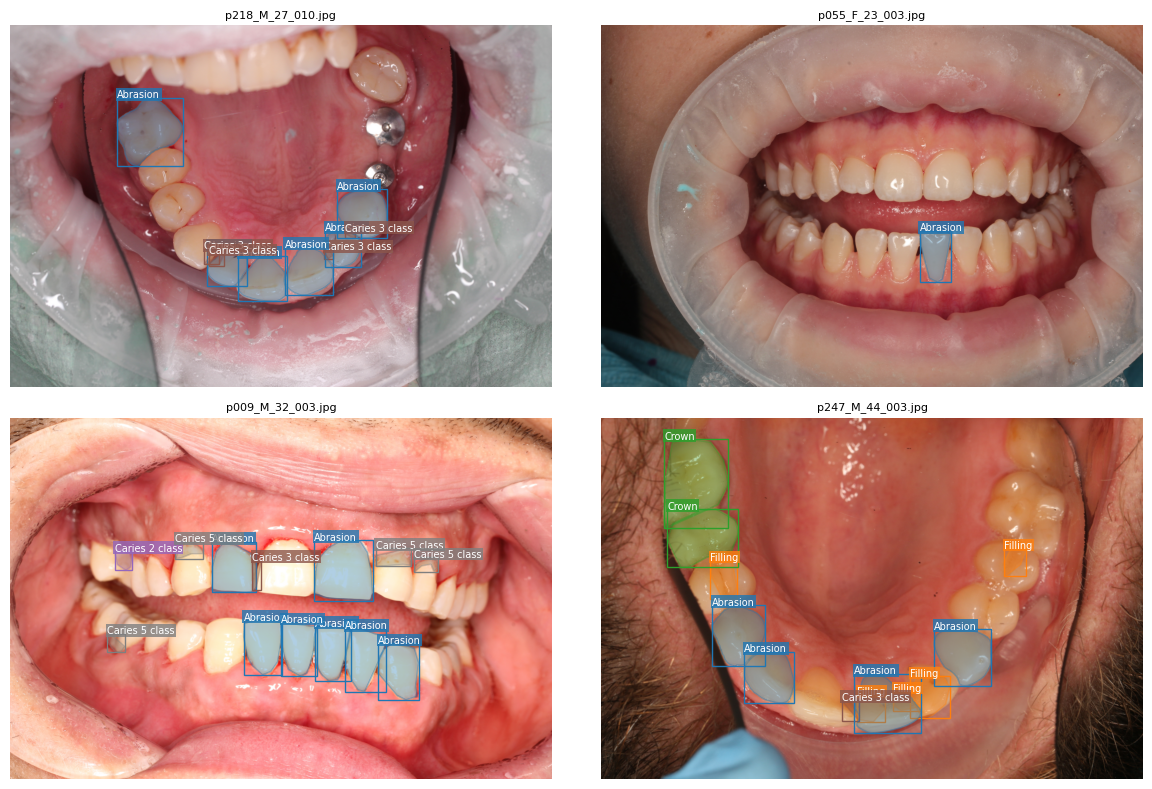

In [ ]:
def plot_ground_truth(image_path, label_path, ax):
    image = Image.open(image_path).convert('RGB')
    w, h = image.size
    ax.imshow(image)
    ax.axis('off')
    ax.set_title(Path(image_path).name, fontsize=8)
    colors = plt.get_cmap('tab10')
    for line in Path(label_path).read_text().splitlines():
        values = line.split()
        if len(values) < 7:
            continue
        cls = int(values[0])
        xy = np.asarray([float(v) for v in values[1:]], dtype=float).reshape(-1, 2)
        px, py = xy[:, 0] * w, xy[:, 1] * h
        color = colors(cls % 10)
        ax.fill(px, py, color=color, alpha=0.35)
        x0, x1, y0, y1 = px.min(), px.max(), py.min(), py.max()
        ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor=color, linewidth=1))
        ax.text(x0, max(y0 - 4, 0), CLASS_NAMES[cls], color='white', fontsize=7, bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor='none'))

train_images = sorted((CUSTOM / 'images' / 'train').glob('*.jpg'))
rng = random.Random(SEED)
samples = rng.sample(train_images, min(4, len(train_images)))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for img_path, ax in zip(samples, axes.ravel()):
    plot_ground_truth(img_path, CUSTOM / 'labels' / 'train' / f'{img_path.stem}.txt', ax)
for ax in axes.ravel()[len(samples):]: ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Arquitectura (YOLOv8n-seg) y entrenamiento

Elegimos YOLOv8n-seg porque hace detección y segmentación de instancias en una sola pasada, que son las dos cosas que pide la consigna, y es lo bastante liviano para entrenar en la GPU T4 de Colab. Según el resumen que imprime Ultralytics al entrenar, tiene 151 capas, 3,27 millones de parámetros y 11,5 GFLOPs.

Cómo está armada (los números de capa son los del resumen del modelo):

1. Backbone (capas 0 a 9). Convoluciones con paso 2 que van achicando la imagen y subiendo los canales (16, 32, 64, 128 y 256), con bloques C2f entre ellas. Al final hay un SPPF, que resume el mapa con ventanas de varios tamaños para dar más contexto. Aquí la red aprende bordes, texturas y formas del diente.
2. Neck (capas 10 a 21). Mezcla los mapas de tres escalas del backbone. Primero va del mapa más profundo (muy abstracto, poca resolución) hacia los más finos con Upsample, Concat y C2f (la parte tipo FPN), y después de los finos hacia los profundos con convoluciones de paso 2 (la parte tipo PAN). Salen tres mapas con 64, 128 y 256 canales, uno para objetos pequeños, otro para medianos y otro para grandes.
3. Cabeza Segment (capa 22). Para cada escala predice la caja (sin anchors, con una rama aparte para la caja y otra para la clase), la probabilidad de cada una de las 9 clases y 32 coeficientes de máscara. Además hay un módulo de prototipos que genera 32 mapas base a un cuarto de la resolución de la imagen. La máscara de cada objeto es la combinación de esos 32 mapas, ponderada con los 32 coeficientes de esa detección, pasada por una sigmoide y recortada a su caja.
4. Pérdida. Es la suma ponderada de la pérdida de la caja (CIoU, peso 7,5), la de la distribución de los bordes (DFL, peso 1,5), la de clasificación (entropía cruzada binaria, peso 0,5) y la de la máscara (entropía cruzada binaria contra la máscara real). Durante el entrenamiento, cada objeto real se asigna a las predicciones que mejor coinciden en clase y posición.

Transfer learning: partimos de yolov8n-seg.pt, preentrenado en COCO (80 clases). Como pasamos a 9 clases, Ultralytics avisa "Overriding nc=80 with nc=9" y "Transferred 411/417 items": se copian 411 de los 417 tensores y los 6 restantes son los de la última capa de clasificación, que depende del número de clases. Así partimos de un backbone que ya sabe ver bordes y texturas, y el entrenamiento ajusta toda la red con nuestras fotos (no congelamos el backbone).

Por qué no Mask R-CNN: es una red de dos etapas (primero propone regiones y luego clasifica y segmenta cada una) y suele ser más precisa con objetos pequeños, pero es más lenta y para entrenar varias veces en Colab elegimos YOLO. No la probamos; quedó como mejora futura.

Parámetros: 50 épocas, batch 8, paciencia 12 (parar si no mejora), semilla 42, optimizador automático (AdamW) y los aumentos de datos por defecto (mosaico, volteo horizontal y cambios de color; el mosaico se apaga las últimas 10 épocas). Usamos cache en RAM porque sin ella cada época tardaba cerca de 3 minutos y con ella unos 25 segundos.

Corridas: la celda de abajo se ejecutó dos veces. La primera con IMGSZ = 640 (35 minutos) y la segunda con IMGSZ = 1024 (46 minutos), cambiando también RUN_NAME. La pregunta del segundo experimento era si las lesiones pequeñas se pierden por bajar la resolución.

In [ ]:
from ultralytics import YOLO

if not torch.cuda.is_available():
    raise RuntimeError('No hay GPU disponible. Activa una GPU en la configuración de Colab antes de entrenar.')

# Cada corrida lleva su RUN_NAME para no pisar los resultados de la otra.
# Corrida 1: IMGSZ = 640,  RUN_NAME = 'alphadent_yolov8n_seg'
# Corrida 2: IMGSZ = 1024, RUN_NAME = 'alphadent_yolov8n_seg_experimento'
MODEL_NAME = 'yolov8n-seg.pt'
EPOCHS = 50
IMGSZ = 1024
BATCH = 8
PATIENCE = 12
RUN_NAME = 'alphadent_yolov8n_seg_experimento'
RUN_DIR = OUT_DIR / 'runs' / RUN_NAME
if RUN_DIR.exists():
    raise FileExistsError(f'Ya existe {RUN_DIR}. Cambia RUN_NAME para no sobrescribir un experimento anterior.')

model = YOLO(MODEL_NAME)  # carga arquitectura + pesos iniciales preentrenados
train_results = model.train(
    data=str(DATA_YAML),
    task='segment',
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    device=0,
    workers=2,
    cache='ram',   # fotos ya redimensionadas en RAM; así no se decodifica el JPG en cada época
    seed=SEED,
    deterministic=True,
    project=str(OUT_DIR / 'runs'),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    close_mosaic=10,
    verbose=True,
)

BEST_WEIGHTS = RUN_DIR / 'weights' / 'best.pt'
LAST_WEIGHTS = RUN_DIR / 'weights' / 'last.pt'
print('Mejores pesos existen:', BEST_WEIGHTS.exists(), BEST_WEIGHTS)
print('Últimos pesos existen:', LAST_WEIGHTS.exists(), LAST_WEIGHTS)
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError('No se encontró best.pt. Revisa los mensajes de entrenamiento y la carpeta de resultados.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/alphadent_custom/alphadent.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fracti

## 7. Evaluación en el conjunto de prueba

Evaluamos con best.pt, que son los pesos de la época con mejor resultado en validación, sobre el conjunto de prueba (45 pacientes que el modelo nunca vio). Reportamos por separado la detección (cajas) y la segmentación (máscaras).

Cómo se leen las métricas:
- IoU: qué tanto se solapan la región predicha y la real (área de la intersección dividida por el área de la unión). Vale 1 si coinciden perfecto.
- Una detección cuenta como acierto si la clase es correcta y el IoU pasa un umbral.
- AP: área bajo la curva precisión-recall de una clase. mAP es el promedio de las 9 clases.
- mAP50 usa el umbral IoU 0,5. mAP50-95 promedia los umbrales de 0,5 a 0,95 y es más exigente porque pide contornos muy ajustados.
- Precisión: de lo que el modelo marcó, cuánto era correcto. Recall: de lo que había, cuánto encontró.

### Resultados que obtuvimos (conjunto de prueba, 1.792 objetos)

| Métrica | 640 px | 1024 px |
|---|---|---|
| mAP50 cajas | 0,292 | 0,321 |
| mAP50-95 cajas | 0,187 | 0,204 |
| mAP50 máscaras | 0,289 | 0,310 |
| mAP50-95 máscaras | 0,166 | 0,185 |
| Tiempo de entrenamiento | 35 min | 46 min |

Son resultados modestos, y era de esperar: el modelo es el más pequeño de la familia, el dataset es difícil y está muy desbalanceado.

In [ ]:
best_model = YOLO(str(BEST_WEIGHTS))
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split='test',
    imgsz=IMGSZ,
    batch=BATCH,
    device=0,
    plots=True,
    project=str(OUT_DIR / 'evaluation'),
    name=f'test_{RUN_NAME}',
    exist_ok=True,
)

def print_metric_group(title, metric_obj):
    print('\n' + title)
    for key, attr in [('Precision', 'mp'), ('Recall', 'mr'), ('mAP@50', 'map50'), ('mAP@50-95', 'map')]:
        value = getattr(metric_obj, attr, None)
        if value is not None:
            print(f'{key}: {float(value):.4f}')

print_metric_group('DETECCIÓN: cajas', test_metrics.box)
print_metric_group('SEGMENTACIÓN: máscaras', test_metrics.seg)

# Guardar un resumen numérico en Drive para el reporte.
summary = {
    'run_name': RUN_NAME,
    'model': MODEL_NAME,
    'epochs_configured': EPOCHS,
    'image_size': IMGSZ,
    'batch': BATCH,
    'box_precision': float(test_metrics.box.mp),
    'box_recall': float(test_metrics.box.mr),
    'box_map50': float(test_metrics.box.map50),
    'box_map50_95': float(test_metrics.box.map),
    'mask_precision': float(test_metrics.seg.mp),
    'mask_recall': float(test_metrics.seg.mr),
    'mask_map50': float(test_metrics.seg.map50),
    'mask_map50_95': float(test_metrics.seg.map),
}
summary_path = OUT_DIR / f'metricas_test_{RUN_NAME}.json'
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print('Resumen guardado en:', summary_path)
print(json.dumps(summary, indent=2, ensure_ascii=False))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,387,067 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 224.1±33.4 MB/s, size: 3448.0 KB)
val: Scanning /content/alphadent_custom/labels/test... 190 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 190/190 165.4it/s 1.1s
val: New cache created: /content/alphadent_custom/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.3s/it 30.3s
                   all        190       1792      0.393      0.378      0.321      0.204      0.384      0.379       0.31      0.185
              Abrasion        163        907      0.597      0.773      0.711      0.626       0.59      0.775      0.706      0.587
               Filling        118        377      0.545      0.618      0.607      0.337      0.536      

## 8. Métricas por clase y desbalance

El promedio general esconde diferencias enormes entre clases. Esta es la tabla de mAP50-95 de máscara por clase para las dos corridas:

| Clase | Objetos en prueba | 640 px | 1024 px |
|---|---|---|---|
| Abrasion | 907 | 0,546 | 0,587 |
| Crown | 81 | 0,486 | 0,480 |
| Filling | 377 | 0,222 | 0,297 |
| Caries 1 | 117 | 0,092 | 0,088 |
| Caries 5 | 97 | 0,091 | 0,136 |
| Caries 2 | 166 | 0,040 | 0,042 |
| Caries 3 | 39 | 0,011 | 0,023 |
| Caries 6 | 6 | 0,002 | 0,009 |
| Caries 4 | 2 | 0,000 | 0,000 |

Abrasion, Crown y Filling son las clases con más ejemplos y las que mejor salen. Caries 4 y Caries 6 tienen 47 y 57 objetos en todo el dataset, y solo 2 y 6 en prueba, así que su resultado depende del azar y no se puede concluir que el modelo no las detecte.

In [ ]:
per_class_map = getattr(test_metrics.seg, 'maps', None)
if per_class_map is not None and len(per_class_map) == len(CLASS_NAMES):
    class_metrics = pd.DataFrame({'clase': CLASS_NAMES, 'mask_mAP50_95': np.asarray(per_class_map, dtype=float)})
    display(class_metrics.sort_values('mask_mAP50_95', ascending=False))
    class_metrics.to_csv(OUT_DIR / f'metricas_por_clase_{RUN_NAME}.csv', index=False)
else:
    print('La versión de Ultralytics no expuso métricas por clase en este objeto. Consulta los archivos de evaluación generados.')

print('Instancias de prueba por clase:')
display(dist[['clase', 'test']].sort_values('test'))

## 9. Predicciones sobre fotos de prueba

Comparamos la anotación real (izquierda) con la predicción del modelo (derecha) en fotos de prueba, con la confianza de cada detección. En los ejemplos que revisamos (corrida de 640 px) vimos tres cosas: el modelo encuentra bien Abrasion y Filling, a veces marca Abrasion en dientes que no lo tienen (más objetos predichos que reales), y llega a confundir Filling con Crown. Las caries pequeñas se detectan solo en parte.

Results saved to /content/drive/MyDrive/miniproyecto_cnn/predicciones/muestras_test_alphadent_yolov8n_seg_experimento


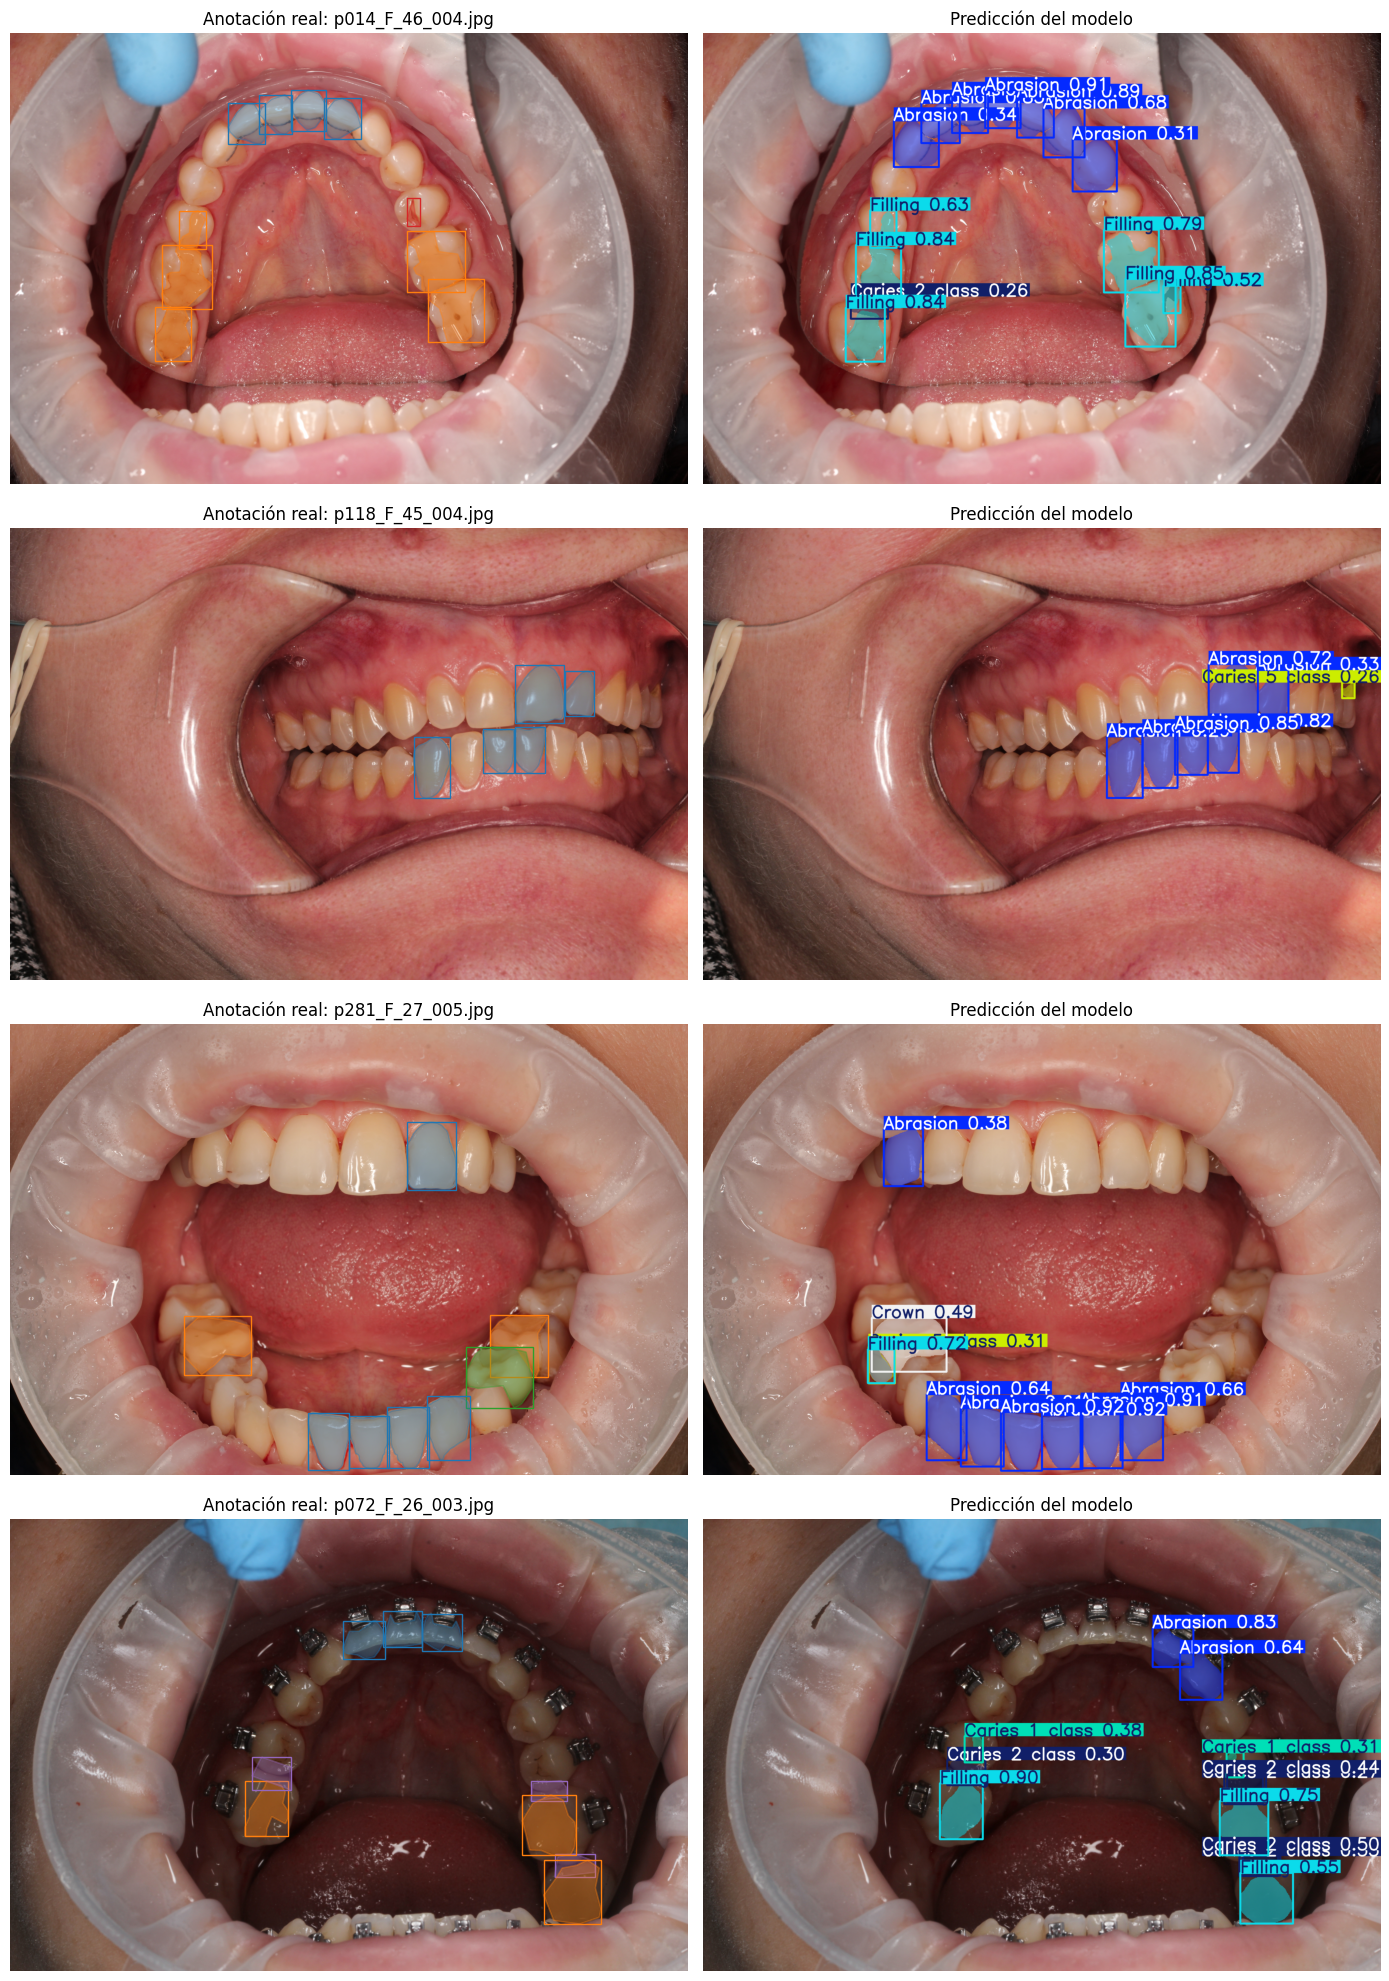

Predicciones guardadas en: /content/drive/MyDrive/miniproyecto_cnn/predicciones/muestras_test


In [ ]:
test_images = sorted((CUSTOM / 'images' / 'test').glob('*.jpg'))
if not test_images:
    raise RuntimeError('No hay imágenes en el conjunto test.')

rng = random.Random(SEED + 1)
pred_samples = rng.sample(test_images, min(4, len(test_images)))
pred_results = best_model.predict(
    source=[str(p) for p in pred_samples],
    imgsz=IMGSZ,
    conf=0.25,
    iou=0.7,
    device=0,
    save=True,
    project=str(OUT_DIR / 'predicciones'),
    name=f'muestras_test_{RUN_NAME}',
    exist_ok=True,
    verbose=False,
)

fig, axes = plt.subplots(len(pred_results), 2, figsize=(14, 5 * len(pred_results)))
if len(pred_results) == 1:
    axes = np.asarray([axes])
for i, (img_path, result) in enumerate(zip(pred_samples, pred_results)):
    gt_ax, pred_ax = axes[i]
    plot_ground_truth(img_path, CUSTOM / 'labels' / 'test' / f'{img_path.stem}.txt', gt_ax)
    gt_ax.set_title(f'Anotación real: {img_path.name}')
    pred_ax.imshow(result.plot()[:, :, ::-1])  # Ultralytics devuelve BGR; Matplotlib espera RGB
    pred_ax.axis('off')
    pred_ax.set_title('Predicción del modelo')
plt.tight_layout(); plt.show()
print('Predicciones guardadas en:', OUT_DIR / 'predicciones' / f'muestras_test_{RUN_NAME}')

### Las tres salidas del modelo para una foto

Para una de las fotos de prueba mostramos en una tabla lo que predice el modelo por cada objeto: la clase (con su confianza), la caja y la máscara (número de vértices de su contorno y su área en píxeles).

In [ ]:
r = pred_results[0]
filas_pred = []
if r.masks is not None:
    for i in range(len(r.boxes)):
        x0, y0, x1, y1 = r.boxes.xyxy[i].tolist()
        poly = r.masks.xy[i]
        area = 0.5 * abs(np.dot(poly[:, 0], np.roll(poly[:, 1], 1)) - np.dot(poly[:, 1], np.roll(poly[:, 0], 1)))
        filas_pred.append({
            'clase': CLASS_NAMES[int(r.boxes.cls[i])],
            'confianza': round(float(r.boxes.conf[i]), 2),
            'caja (x0, y0, x1, y1)': tuple(round(v) for v in (x0, y0, x1, y1)),
            'vértices de la máscara': len(poly),
            'área de la máscara (px)': int(area),
        })
print('Foto:', Path(pred_samples[0]).name)
display(pd.DataFrame(filas_pred))

Foto: p014_F_46_004.jpg


,clase,confianza,"caja (x0, y0, x1, y1)",vértices de la máscara,área de la máscara (px)
0,Abrasion,0.91,"(2158, 446, 2429, 736)",52,55168
1,Abrasion,0.89,"(2402, 497, 2682, 808)",74,61892
2,Abrasion,0.86,"(1904, 481, 2180, 772)",61,55908
3,Filling,0.85,"(3229, 1888, 3614, 2405)",110,130368
4,Filling,0.84,"(1092, 2110, 1390, 2520)",89,76032
5,Filling,0.84,"(1169, 1629, 1514, 2104)",110,95808
6,Abrasion,0.83,"(1670, 543, 1963, 850)",67,61284
7,Filling,0.79,"(3066, 1511, 3486, 1991)",141,108960
8,Abrasion,0.68,"(2603, 583, 2917, 958)",72,87872
9,Filling,0.63,"(1278, 1365, 1479, 1651)",52,27332


## 10. Curvas de entrenamiento y matriz de confusión

Ultralytics guarda en la carpeta de cada corrida las gráficas de pérdidas, la matriz de confusión y las curvas precisión-recall. Esto es lo que vimos en la corrida de 640 px:

- Las pérdidas de entrenamiento bajan durante las 50 épocas. Las de validación se aplanan hacia la mitad, y la de clasificación empieza a subir después de la época 37 (1,054 en el mínimo y 1,092 al final), mientras la de entrenamiento llega a 0,744. Es un sobreajuste leve: el mAP siguió mejorando hasta la época 40 y la mejor época fue esa.
- En la matriz de confusión (columnas = clase real), Abrasion se acierta el 88 % de las veces. El 44 % de las coronas reales se predicen como Abrasion, los niveles de caries se confunden con los vecinos (el 50 % de Caries 6 se predice como Caries 1) y entre el 5 % y el 33 % de los objetos de cada clase de caries se pierde como fondo.
- La curva precisión-recall confirma el orden de las clases: Abrasion 0,701, Crown 0,595, Filling 0,522, y todas las caries por debajo de 0,3.
- La curva F1 contra confianza muestra que el mejor umbral global es 0,19 (F1 de 0,34) y que cada clase prefiere uno distinto: Abrasion rinde mejor cerca de 0,5 y las caries cerca de 0,2 a 0,3.

In [ ]:
from IPython.display import display, Image as IPyImage

for filename in ('results.png', 'confusion_matrix.png', 'BoxPR_curve.png', 'MaskPR_curve.png'):
    path = RUN_DIR / filename
    if path.exists():
        print(filename)
        display(IPyImage(filename=str(path)))
    else:
        print('No se generó este archivo:', filename)
print('Carpeta de entrenamiento:', RUN_DIR)

## 11. Discusión de resultados y limitaciones

Funcionó parcialmente. El modelo segmenta y detecta bien las clases con muchos ejemplos (Abrasion, Crown y Filling) y casi no logra las caries. El mAP50-95 de máscara pasó de 0,166 a 0,185 al subir de 640 a 1024 px.

Por qué falla en las caries. Estas son las explicaciones que creemos, que son hipótesis y no las comprobamos con experimentos aparte:
- Desbalance: Abrasion tiene 6.347 objetos y Caries 4 solo 47. Con tan pocos ejemplos la red casi no aprende esas clases.
- Los seis niveles de caries son grados de severidad, y niveles vecinos se ven muy parecidos; por eso la matriz de confusión los mezcla entre ellos.
- Las lesiones son pequeñas (las de Caries 3 y Caries 6 miden cerca del 3 % del ancho de la foto) y hay cambios de iluminación y de ángulo entre fotos.
- El modelo es el más pequeño de la familia (3,3 millones de parámetros).

Qué pasó al subir la resolución. Mejoraron Filling (de 0,222 a 0,297), Caries 5 (de 0,091 a 0,136) y Abrasion (de 0,546 a 0,587), y Caries 1 y Caries 2 casi no cambiaron. Entonces la resolución ayuda, pero no explica todo: lo que más limita a las caries parece ser la ambigüedad entre niveles y la falta de ejemplos. A cambio, cada época costó más tiempo (46 contra 35 minutos en total).

Sobreajuste. Hubo uno leve: la pérdida de clasificación en validación sube al final mientras la de entrenamiento sigue bajando (en la corrida de 1024 px el mínimo fue en la época 23). Aun así el mAP seguía mejorando, por eso usamos best.pt y no los últimos pesos.

Limitaciones. Solo hicimos dos corridas, una por configuración, así que diferencias como 0,02 de mAP pueden deberse al azar de la inicialización. El conjunto de prueba es pequeño y deja muy pocos ejemplos de las clases raras. No probamos otra arquitectura. El modelo no es una herramienta clínica.

Cómo mejoraríamos. Más ejemplos de las caries raras o repetir en entrenamiento las fotos que las contienen, un modelo más grande (yolov8s o m), comparar con Mask R-CNN, elegir un umbral de confianza por clase usando validación, y agrupar los niveles de caries en menos categorías para comprobar si la confusión viene de la severidad.

### Las tres salidas que pide la consigna

- Clase: la cabeza de clasificación da la probabilidad de cada una de las 9 clases y se toma la mayor.
- Coordenadas: la cabeza de detección predice la caja. En las etiquetas originales la caja se calcula con los extremos del polígono.
- Máscara: se arma combinando los 32 mapas de prototipos con los 32 coeficientes de cada detección. En el entrenamiento la supervisan los polígonos normalizados del dataset.

### Referencias

- Dataset AlphaDent: https://www.kaggle.com/competitions/alpha-dent/data
- Repositorio del dataset: https://github.com/ZFTurbo/AlphaDent
- Artículo del dataset: https://arxiv.org/abs/2507.22512
- Documentación de Ultralytics: https://docs.ultralytics.com

## 12. Comparación entre experimentos

Tabla con todas las corridas guardadas en Drive (una fila por `metricas_test_<RUN_NAME>.json`). Va directo al reporte.

In [ ]:
rows = [json.loads(p.read_text()) for p in sorted(OUT_DIR.glob('metricas_test_*.json'))]
comp = pd.DataFrame(rows)
cols = [c for c in ['run_name', 'model', 'image_size', 'box_map50', 'box_map50_95', 'mask_map50', 'mask_map50_95'] if c in comp.columns]
display(comp[cols].round(3))
comp[cols].to_csv(OUT_DIR / 'comparacion_experimentos.csv', index=False)

,run_name,model,image_size,box_map50,box_map50_95,mask_map50,mask_map50_95
0,alphadent_yolov8n_seg,yolov8n-seg.pt,640,0.292,0.187,0.289,0.166
1,alphadent_yolov8n_seg_experimento,yolov8n-seg.pt,1024,0.321,0.204,0.310,0.185
